In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
import pandas as pd

from popy.io_tools import load_behavior
from popy.behavior_data_tools import (
    drop_time_fields,
    add_foraging_value,
    add_RL_values,
    add_switch_info,
)
from popy.config import COLORS, PROJECT_PATH_LOCAL

plt.rcParams.update({'font.size': 8})

/home/uzsombi/.config/matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /tmp/matplotlib-e_i3fgiz because there was an issue with the default path (/home/uzsombi/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


In [8]:
def get_behavior():
    behav = load_behavior()
    behav = drop_time_fields(behav)
    behav = behav.dropna(subset=['target'])

    behav = add_foraging_value(behav)
    behav = add_RL_values(behav)

    behav = add_switch_info(behav, add_trials_since_switch=True)

    #cols_to_keep = ['monkey', 'session', 'trial_id', 'feedback']
    #behav = behav[cols_to_keep]

    return behav


In [3]:
save_dir = os.path.join(PROJECT_PATH_LOCAL, 'notebooks', 'behav_modeling', 'figs', 'pred_error')
os.makedirs(save_dir, exist_ok=True)

behav = get_behavior()

behav

,monkey,session,trial_id,block_id,best_target,target,feedback,stay_value,V0,Q_1,Q_2,Q_3,switch,trials_since_switch
0,ka,010720,0,0,2,3.0,1.0,0.110103,0.188963,0.000000,0.000000,0.000000,NaN,0
1,ka,010720,1,0,2,3.0,0.0,0.501630,0.188963,0.000000,0.000000,0.255797,0.0,1
2,ka,010720,2,0,2,1.0,1.0,0.280929,0.188963,0.255797,0.255797,0.190365,1.0,0
3,ka,010720,3,0,2,1.0,0.0,0.501630,0.188963,0.446161,0.190365,0.141670,0.0,1
4,ka,010720,4,0,2,3.0,1.0,0.280929,0.188963,0.332035,0.397467,0.361228,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39170,po,310822,419,9,2,1.0,0.0,0.595735,0.188963,0.767624,0.436690,0.232394,0.0,2
39171,po,310822,420,9,2,1.0,1.0,0.420597,0.188963,0.509311,0.626249,0.490701,0.0,3
39172,po,310822,421,9,2,1.0,1.0,0.590934,0.188963,0.674433,0.415510,0.325575,0.0,4
39173,po,310822,422,9,2,1.0,1.0,0.711194,0.188963,0.783989,0.275687,0.216016,0.0,5


In [4]:
# get chosen q-value: for each row get 'target', convert to int, get r'Q_{target}', and store in new column 'chosen_qvalue'
behav['chosen_qvalue'] = behav.apply(lambda row: row[f'Q_{int(row["target"])}'], axis=1)
behav['value_diff'] = behav.apply(lambda row: row[f'Q_{int(row["target"])}'] - row['stay_value'], axis=1)

# remove V0, Q1, Q2, Q3
behav = behav.drop(columns=['V0', 'Q_1', 'Q_2', 'Q_3', 'block_id', 'best_target', 'feedback'])

behav

,monkey,session,trial_id,target,stay_value,switch,trials_since_switch,chosen_qvalue,value_diff
0,ka,010720,0,3.0,0.110103,NaN,0,0.000000,-0.110103
1,ka,010720,1,3.0,0.501630,0.0,1,0.255797,-0.245834
2,ka,010720,2,1.0,0.280929,1.0,0,0.255797,-0.025132
3,ka,010720,3,1.0,0.501630,0.0,1,0.446161,-0.055469
4,ka,010720,4,3.0,0.280929,1.0,0,0.361228,0.080299
...,...,...,...,...,...,...,...,...,...
39170,po,310822,419,1.0,0.595735,0.0,2,0.767624,0.171889
39171,po,310822,420,1.0,0.420597,0.0,3,0.509311,0.088714
39172,po,310822,421,1.0,0.590934,0.0,4,0.674433,0.083499
39173,po,310822,422,1.0,0.711194,0.0,5,0.783989,0.072795


Text(0, 0.5, 'Chosen Q-value')

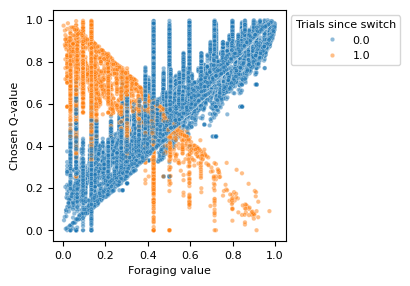

In [18]:
# plot stay_value vs chosen_qvalue, color by switch trials 
fig, ax = plt.subplots(figsize=(3, 3)) 

sns.scatterplot(data=behav, x='stay_value', y='chosen_qvalue', 
                ax=ax, alpha=0.5, s=10, hue='switch')

ax.legend(title='Trials since switch', loc='upper left', bbox_to_anchor=(1, 1))

ax.set_xlabel('Foraging value')
ax.set_ylabel('Chosen Q-value')

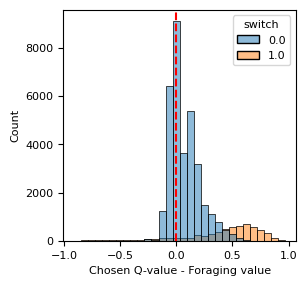

In [24]:
# plot distribution of value_diff, conditioned on switch trials
fig, ax = plt.subplots(figsize=(3, 3))
sns.histplot(data=behav, x='value_diff', hue='switch', bins=30, ax=ax)
ax.set_xlabel('Chosen Q-value - Foraging value')    
ax.axvline(0, color='red', linestyle='--', label='0')